# 02. 상관차원과 리아프노프 지수 (금, Gold)

- 원본(2025-2 투자공학 과제): 금 월간 가격을 CPI와 시간 추세로 회귀해 추세를 뺀 값(Detrended)으로 상관차원과 리아프노프 지수를 구했다. 비교 대상은 한 번 섞은 계열이었다.
- 섞기는 시계열의 자기상관까지 없앤다. 그래서 '섞은 것과 다르다'는 카오스가 아니라 단순한 자기상관만으로도 나올 수 있다.
- 여기서는 **위상 무작위화 대리계열(phase-randomized surrogate)** 을 추가한다. 이 계열은 자기상관(파워 스펙트럼)은 같고 비선형 구조만 없앤 것이다. 실제 계열이 이것과도 다를 때만 비선형 결정론의 증거로 본다.
- 대리계열 19개 → 단측 순위 검정 최소 p = 0.05.

In [1]:
import sys, yaml
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
CFG = yaml.safe_load(open(ROOT / "configs/base.yaml"))
RES = ROOT / "results"; (RES / "figures").mkdir(parents=True, exist_ok=True)
from market_memory.chaos import (correlation_dimension, detrend_with_cpi, lyapunov_rosenstein,
                                  phase_surrogate, shuffle_surrogate, zscore)
C = CFG["chaos"]
gold = pd.read_csv(ROOT / C["gold_file"], parse_dates=["Date"]).set_index("Date")["Price"].dropna()
cpi = pd.read_csv(ROOT / C["cpi_file"], parse_dates=["DATE"]).set_index("DATE")["CPIAUCSL"]
monthly = gold.resample("MS").first().dropna()
detr = detrend_with_cpi(monthly, cpi)
daily_ret = np.log(gold / gold.shift(1)).dropna().iloc[-C["daily_window"]:]
SERIES = {"월간 추세 제거 가격": zscore(detr.values), f"일간 로그수익률(최근 {C['daily_window']}일)": zscore(daily_ret.values)}
print(f"월간: {detr.index.min().date()} ~ {detr.index.max().date()}, N={len(detr)}")
print(f"일간: {daily_ret.index.min().date()} ~ {daily_ret.index.max().date()}, N={len(daily_ret)}")

월간: 2000-08-01 ~ 2025-08-01, N=301
일간: 2017-10-30 ~ 2025-10-13, N=2000


## 1. 상관차원 D2(m): 실제 vs 섞기 vs 위상 무작위화

In [2]:
radii = np.logspace(-2, 0.7, 40)
m_values = list(range(C["m_range"][0], C["m_range"][1] + 1))
rng = np.random.default_rng(C["seed"])
d2 = {}
for name, x in SERIES.items():
    sh = [shuffle_surrogate(x, rng) for _ in range(C["n_surrogates"])]
    ph = [phase_surrogate(x, rng) for _ in range(C["n_surrogates"])]
    rows = []
    for m in m_values:
        obs = correlation_dimension(x, m, radii, C["tau"])
        s_sh = np.array([correlation_dimension(s, m, radii, C["tau"]) for s in sh])
        s_ph = np.array([correlation_dimension(s, m, radii, C["tau"]) for s in ph])
        rows.append({"m": m, "실제": obs, "섞기 평균": np.nanmean(s_sh), "섞기 최소": np.nanmin(s_sh),
                     "위상 평균": np.nanmean(s_ph), "위상 최소": np.nanmin(s_ph),
                     "p(섞기보다 작음)": (np.sum(s_sh <= obs) + 1) / (len(s_sh) + 1),
                     "p(위상보다 작음)": (np.sum(s_ph <= obs) + 1) / (len(s_ph) + 1)})
    d2[name] = pd.DataFrame(rows).set_index("m")
    d2[name].to_csv(RES / f"d2_{'monthly' if '월간' in name else 'daily'}.csv")
    print(name); display(d2[name].round(3))

월간 추세 제거 가격


,실제,섞기 평균,섞기 최소,위상 평균,위상 최소,p(섞기보다 작음),p(위상보다 작음)
m,,,,,,,
1,0.983,0.983,0.983,0.995,0.968,1.00,0.20
2,1.911,2.011,1.867,1.896,1.833,0.15,0.65
3,2.512,2.828,2.709,2.674,2.496,0.05,0.10
4,3.078,3.529,3.423,3.229,2.958,0.05,0.20
5,3.458,4.202,3.993,3.664,3.295,0.05,0.20
6,3.529,4.832,4.500,3.938,3.551,0.05,0.05
7,3.803,5.441,4.962,4.205,3.887,0.05,0.05
8,3.892,5.929,5.489,4.336,3.637,0.05,0.10
9,4.175,6.396,5.839,4.539,3.970,0.05,0.25


일간 로그수익률(최근 2000일)


,실제,섞기 평균,섞기 최소,위상 평균,위상 최소,p(섞기보다 작음),p(위상보다 작음)
m,,,,,,,
1,0.997,0.997,0.997,0.999,0.994,1.00,0.25
2,1.969,1.969,1.957,1.979,1.965,0.50,0.20
3,2.850,2.859,2.839,2.892,2.866,0.35,0.05
4,3.594,3.622,3.573,3.741,3.692,0.20,0.05
5,4.218,4.301,4.193,4.502,4.452,0.10,0.05
6,4.960,4.765,4.599,5.134,5.031,1.00,0.05
7,5.386,5.383,5.180,5.822,5.689,0.50,0.05
8,5.860,5.718,5.503,6.483,6.302,0.80,0.05
9,5.915,6.256,6.090,6.769,6.632,0.05,0.05


## 2. 최대 리아프노프 지수 (Rosenstein)

In [3]:
L = C["lyap"]
stat = lambda x: lyapunov_rosenstein(x, m=L["m"], tau=L["tau"], max_t=L["max_t"], fit_range=tuple(L["fit_range"]))["lyap"]
rng = np.random.default_rng(C["seed"] + 1)
ly_rows, curves = [], {}
for name, x in SERIES.items():
    obs = lyapunov_rosenstein(x, m=L["m"], tau=L["tau"], max_t=L["max_t"], fit_range=tuple(L["fit_range"]))
    curves[name] = obs["log_div"]
    for kind, gen in [("섞기", shuffle_surrogate), ("위상", phase_surrogate)]:
        s = np.array([stat(gen(x, rng)) for _ in range(C["n_surrogates"])])
        ly_rows.append({"계열": name, "대리계열": kind, "실제 λ": obs["lyap"], "대리 평균": s.mean(), "대리 최소": s.min(),
                        "대리 최대": s.max(), "p(대리보다 큼)": (np.sum(s >= obs["lyap"]) + 1) / (len(s) + 1),
                        "p(대리보다 작음)": (np.sum(s <= obs["lyap"]) + 1) / (len(s) + 1)})
ly = pd.DataFrame(ly_rows)
ly.to_csv(RES / "lyapunov.csv", index=False)
ly.round(4)

,계열,대리계열,실제 λ,대리 평균,대리 최소,대리 최대,p(대리보다 큼),p(대리보다 작음)
0,월간 추세 제거 가격,섞기,0.1072,0.0371,0.0322,0.0427,0.05,1.00
1,월간 추세 제거 가격,위상,0.1072,0.0974,0.0868,0.1105,0.25,0.80
2,일간 로그수익률(최근 2000일),섞기,0.0423,0.0440,0.0417,0.0474,0.90,0.15
3,일간 로그수익률(최근 2000일),위상,0.0423,0.0434,0.0422,0.0445,0.95,0.10


## 3. 요약표

In [4]:
lines = ["| 계열 | N | D2(m=10) 실제 | 섞기 평균 | 위상 평균 | p(위상보다 작음) | λ 실제 | λ 위상 평균 | p(λ가 위상보다 큼) |", "|---|---|---|---|---|---|---|---|---|"]
for name, x in SERIES.items():
    r = d2[name].loc[m_values[-1]]
    l = ly[(ly["계열"] == name) & (ly["대리계열"] == "위상")].iloc[0]
    lines.append(f"| {name} | {len(x)} | {r['실제']:.2f} | {r['섞기 평균']:.2f} | {r['위상 평균']:.2f} | {r['p(위상보다 작음)']:.2f} | "
                 f"{l['실제 λ']:.4f} | {l['대리 평균']:.4f} | {l['p(대리보다 큼)']:.2f} |")
md_t = "\n".join(lines)
(RES / "chaos_summary.md").write_text(md_t + "\n")
print(md_t)

| 계열 | N | D2(m=10) 실제 | 섞기 평균 | 위상 평균 | p(위상보다 작음) | λ 실제 | λ 위상 평균 | p(λ가 위상보다 큼) |
|---|---|---|---|---|---|---|---|---|
| 월간 추세 제거 가격 | 301 | 4.14 | 6.90 | 4.59 | 0.10 | 0.1072 | 0.0974 | 0.25 |
| 일간 로그수익률(최근 2000일) | 2000 | 6.54 | 6.56 | 7.46 | 0.05 | 0.0423 | 0.0434 | 0.95 |


## 4. 그림

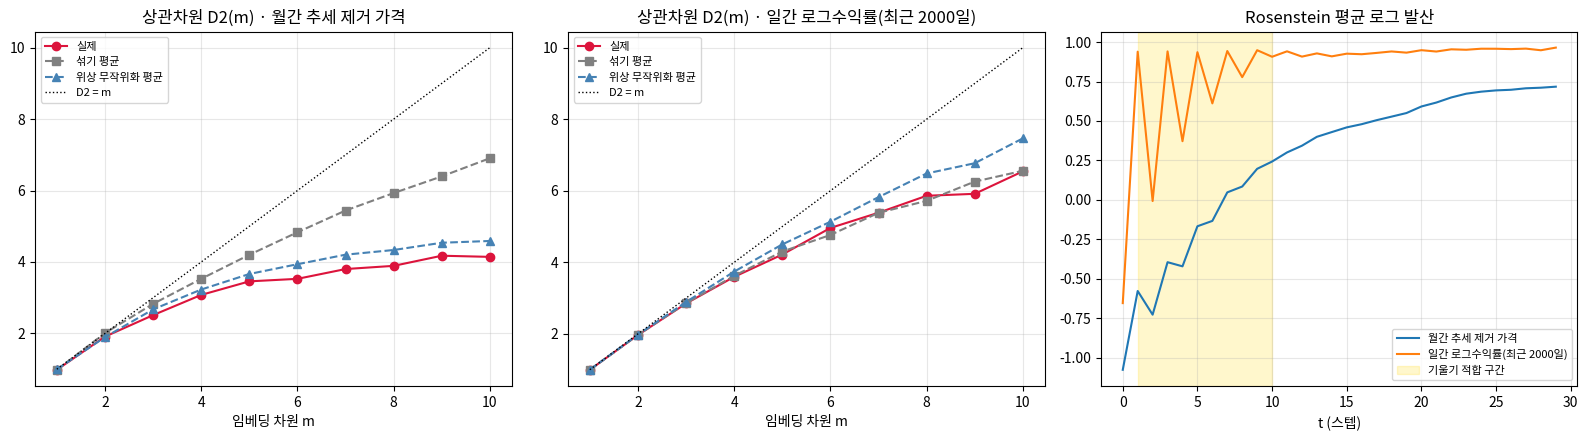

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, t) in zip(axes[:2], d2.items()):
    ax.plot(t.index, t["실제"], "o-", color="crimson", label="실제")
    ax.plot(t.index, t["섞기 평균"], "s--", color="gray", label="섞기 평균")
    ax.plot(t.index, t["위상 평균"], "^--", color="steelblue", label="위상 무작위화 평균")
    ax.plot(t.index, t.index, ":", color="k", lw=1, label="D2 = m")
    ax.set_title(f"상관차원 D2(m) · {name}"); ax.set_xlabel("임베딩 차원 m"); ax.legend(fontsize=8); ax.grid(alpha=.3)
for name, c in curves.items():
    axes[2].plot(np.arange(len(c)), c, label=name)
lo, hi = CFG["chaos"]["lyap"]["fit_range"]
axes[2].axvspan(lo, hi, color="gold", alpha=.2, label="기울기 적합 구간")
axes[2].set_title("Rosenstein 평균 로그 발산"); axes[2].set_xlabel("t (스텝)"); axes[2].legend(fontsize=8); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "figures/chaos_overview.png", dpi=150); plt.show()